## Part 1: Analyzing Best-Seller Trends Across Product Categories



In [1]:
#1 Crosstab Analysis
# Contingency Table analysis, is a method used to examine the relationship between two or more categorical variables

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

df_Amazon = pd.read_csv("/Users/chiara/Ironhack/week5/Day1/Exercises/amz_uk_price_prediction_dataset.csv")


**Objective: Understand the relationship between product categories and their best-seller status**

# Crosstab Analysis:

- Create a crosstab between the product category and the isBestSeller status.

- Are there categories where being a best-seller is more prevalent?

- Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.



In [2]:
df_Amazon

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [4]:
freq_table_category = df_Amazon['category'].value_counts()
freq_table_category


category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [5]:
freq_table_bs = df_Amazon['isBestSeller'].value_counts()
freq_table_bs 

isBestSeller
False    2435671
True        7980
Name: count, dtype: int64

In [6]:
#pd.crosstab() creates a table that counts the occurrences of each combination of categories

cross_tab = pd.crosstab(df_Amazon['category'],df_Amazon['isBestSeller'])
print (cross_tab)

isBestSeller                    False  True 
category                                    
3D Printers                       247      1
3D Printing & Scanning           4065      2
Abrasive & Finishing Products     245      5
Action Cameras                   1696      1
Adapters                          251      3
...                               ...    ...
Wind Instruments                  243      7
Window Treatments                 234      5
Women                           17559    213
Women's Sports & Outdoor Shoes   1939     20
eBook Readers & Accessories       246      0

[296 rows x 2 columns]


In [7]:
#calculate rate of bs per each category

best_seller_count = df_Amazon[df_Amazon['isBestSeller']].groupby('category').size()
best_seller_count


category
3D Printers                         1
3D Printing & Scanning              2
Abrasive & Finishing Products       5
Action Cameras                      1
Adapters                            3
                                 ... 
Wearable Technology                30
Wind Instruments                    7
Window Treatments                   5
Women                             213
Women's Sports & Outdoor Shoes     20
Length: 260, dtype: int64

In [8]:
tot_count = df_Amazon.groupby('category').size()
tot_count 


category
3D Printers                         248
3D Printing & Scanning             4067
Abrasive & Finishing Products       250
Action Cameras                     1697
Adapters                            254
                                  ...  
Wind Instruments                    250
Window Treatments                   239
Women                             17772
Women's Sports & Outdoor Shoes     1959
eBook Readers & Accessories         246
Length: 296, dtype: int64

In [9]:
best_seller_percentage = ((best_seller_count / tot_count) * 100).round(2).sort_values(ascending = False)

print(best_seller_percentage)

category
Grocery                           5.81
Smart Home Security & Lighting    5.77
Health & Personal Care            5.77
Mobile Phone Accessories          4.25
Power & Hand Tools                3.53
                                  ... 
Snowboard Boots                    NaN
Toy Advent Calendars               NaN
USB Gadgets                        NaN
Vases                              NaN
eBook Readers & Accessories        NaN
Length: 296, dtype: float64


In [10]:
#2
#the best sellers are more prevalent in grocery category and in smart home security & lighting 

**Statistical Tests**:

- Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
- Compute Cramér's V to understand the strength of association between best-seller status and category.

**The Chi-square test is used to determine if there is a significant association between two categorical variables—in this case, the isBestSeller status and the ProductCategory**

-Formulate Hypotheses:

-Null Hypothesis ((H_0)): The distribution of best-seller status is independent of the product category (no association).
-Alternative Hypothesis ((H_1)): The distribution of best-seller status is dependent on the product category (there is an association).

-Create a Contingency Table:

-Organize your data in a table format that counts occurrences of each combination of categories (like you would in a crosstab).
Perform the Chi-Square Test:

-You'll use the Chi-square test to compare observed frequencies in your contingency table with the frequencies you would expect if there were no association.
Analyze the Result:

-Look at the p-value from the test. If the p-value is below a certain threshold (commonly 0.05), you reject the null hypothesis, suggesting an association.

In [15]:
import pandas as pd
from scipy.stats import chi2_contingency

cross_tab = pd.crosstab(df_Amazon['category'],df_Amazon['isBestSeller'])

chi2_stat, p_val, dof, expected = chi2_contingency(cross_tab)

print(f"Chi-square Statistic: {chi2_stat}")

if p_val < 0.05:   #p-values depend on the distribution's shape determined by the dof.
    print("Reject the null hypothesis. There is an association between the variables.")
else:
    print("Fail to reject the null hypothesis. There is no significant association between the variables.")

Chi-square Statistic: 36540.20270061387
Reject the null hypothesis. There is an association between the variables.


**chi2_stat (Chi-square Statistic)**

-This value measures how much the observed counts in your contingency table deviate from the expected counts under the null hypothesis.
A larger Chi-square statistic indicates a larger difference between observed and expected values, which could suggest an association between the variables.

**P-value**

-A small p-value (typically ≤ 0.05) suggests that the variables are likely associated. Essentially, it gives you evidence against the null hypothesis.

**dof (Degrees of Freedom)**

- Degrees of freedom are related to the number of categories in your contingency table

**expected (Expected Frequencies)**

- These are the counts you would expect if there were no association between the variables. They're calculated based on the marginal totals of the contingency table.
Comparing observed to expected frequencies gives insight into how good the fit is between your data and the model of independence.


In [16]:
N = cross_tab.sum().sum() #total Number of Observations (N):This is simply the sum of all frequencies in your contingency table


In [17]:
#Find the Minimum of Rows and Columns Minus One:
# Min value of (rows - 1) and (columns - 1)

k = min(cross_tab.shape) - 1

In [18]:
# Calculate Cramér's V
cramers_v = np.sqrt(chi2_stat / (N * k))

print(f"Cramér's V: {cramers_v}")

Cramér's V: 0.1222829439760564


In [ ]:
#Cramér's V value close to 0: Indicates a weak association between the variables  
#Cramér's V value close to 1: Indicates a strong association.

#weak influence : randomness / Other variables or factors might play a more significant role in influencing the best-seller status

In [ ]:
#3 


**Visualizations**

- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

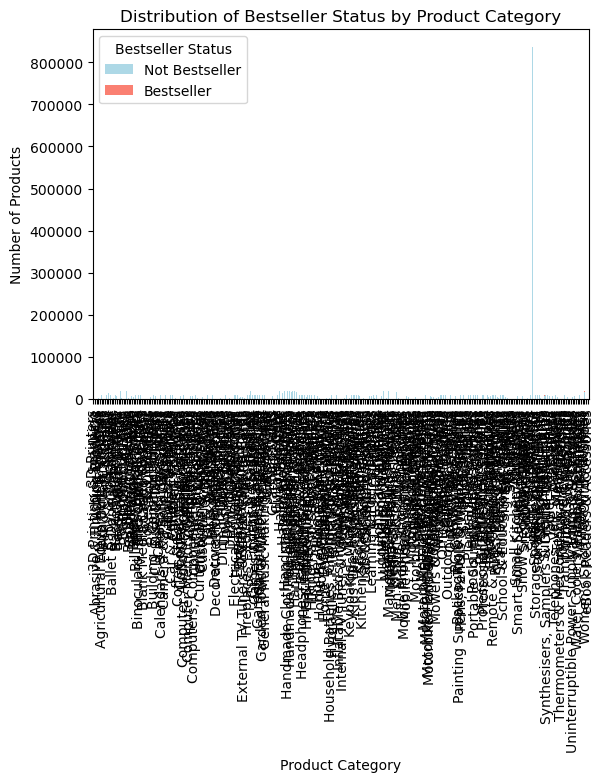

In [19]:
# or heatmap

category_counts = df_Amazon.groupby(['category', 'isBestSeller']).size().unstack(fill_value=0)

# Step 2: Plot the data
category_counts.plot(
    kind='bar',
    stacked=True,
    color=['lightblue', 'salmon'],
    title='Distribution of Bestseller Status by Product Category'
)

plt.xlabel('Product Category')
plt.ylabel('Number of Products')
plt.legend(title='Bestseller Status', labels=['Not Bestseller', 'Bestseller'])
plt.show()


In [21]:
df_Amazon['category'].nunique()

296

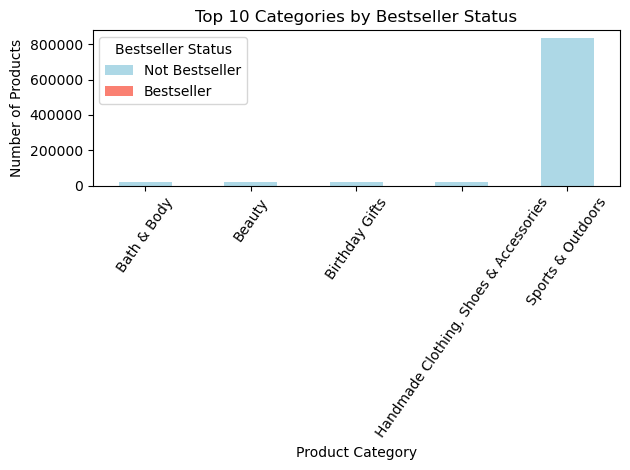

In [29]:
# filter out the major categories 

# Step 1: Identify top 10 categories based on total counts
top_categories = df_Amazon['category'].value_counts().head(5).index

# Step 2: Filter the DataFrame for these top categories
filtered_df = df_Amazon[df_Amazon['category'].isin(top_categories)]

# Step 3: Prepare pivot table for plotting
category_counts = filtered_df.groupby(['category', 'isBestSeller']).size().unstack(fill_value=0)


# Step 4: Plot the data
category_counts.plot(
    kind='bar',
    stacked=True,
    color=['lightblue', 'salmon'],
    title='Top 10 Categories by Bestseller Status'
)

plt.xlabel('Product Category')
plt.ylabel('Number of Products')
plt.legend(title='Bestseller Status', labels=['Not Bestseller', 'Bestseller'])
plt.xticks(rotation=55)
plt.tight_layout()
plt.show()


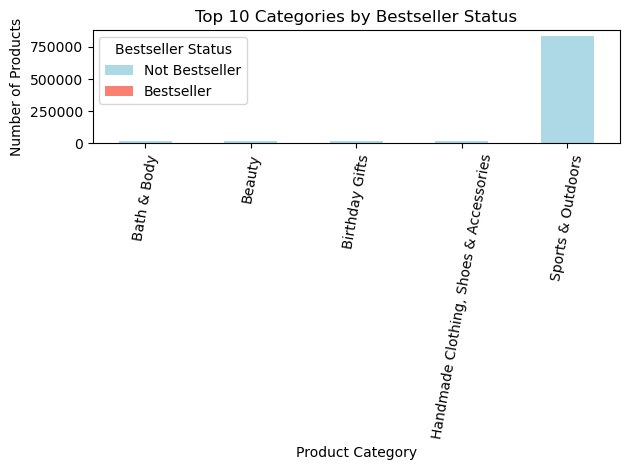

In [33]:
#Plot the bars in terms of percentage of each category, which helps to make variations more apparent even if absolute differences are small.

# Step 1: Identify top 10 categories based on total counts
top_categories = df_Amazon['category'].value_counts().head(5).index

# Step 2: Filter the DataFrame for these top categories
filtered_df = df_Amazon[df_Amazon['category'].isin(top_categories)]

# Step 3: Prepare pivot table for plotting
category_counts = filtered_df.groupby(['category', 'isBestSeller']).size().unstack(fill_value=0)

category_percentage = category_counts.div(category_counts.sum(axis=1), axis=0) * 100

# Step 4: Plot the data
category_counts.plot(
    kind='bar',
    stacked=True,
    color=['lightblue', 'salmon'],
    title='Top 10 Categories by Bestseller Status'
)

plt.xlabel('Product Category')
plt.ylabel('Number of Products')
plt.legend(title='Bestseller Status', labels=['Not Bestseller', 'Bestseller'])
plt.xticks(rotation=80)
plt.tight_layout()
plt.show()

## Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective: Investigate how different product categories influence product prices**

In [34]:
quantiles_price = df_Amazon['price'].quantile([0.25, 0.5, 0.75])
quantiles_price

0.25     9.99
0.50    19.09
0.75    45.99
Name: price, dtype: float64

In [37]:
#The Interquartile Range (IQR) method is a common statistical technique for identifying outliers. It helps to ensure that your analysis isn't skewed by extreme values.
# IQR = Q3 - Q1
# Lower Bound: Q1 - 1.5 * IQR
# Upper Bound: Q3 + 1.5 * IQR

q1 = df_Amazon['price'].quantile(0.25)
q3 = df_Amazon['price'].quantile(0.75)
IQR = q3-q1

lower_bound = q1 - 1.5 * IQR
upper_bound = q3 + 1.5 * IQR

In [39]:
# remove outliers
# & vs and --> AND process single Boolean values, not arrays or Series objects

filtered_df = df_Amazon[(df_Amazon['price'] >= lower_bound) & (df_Amazon['price']<= upper_bound)]
filtered_df 

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


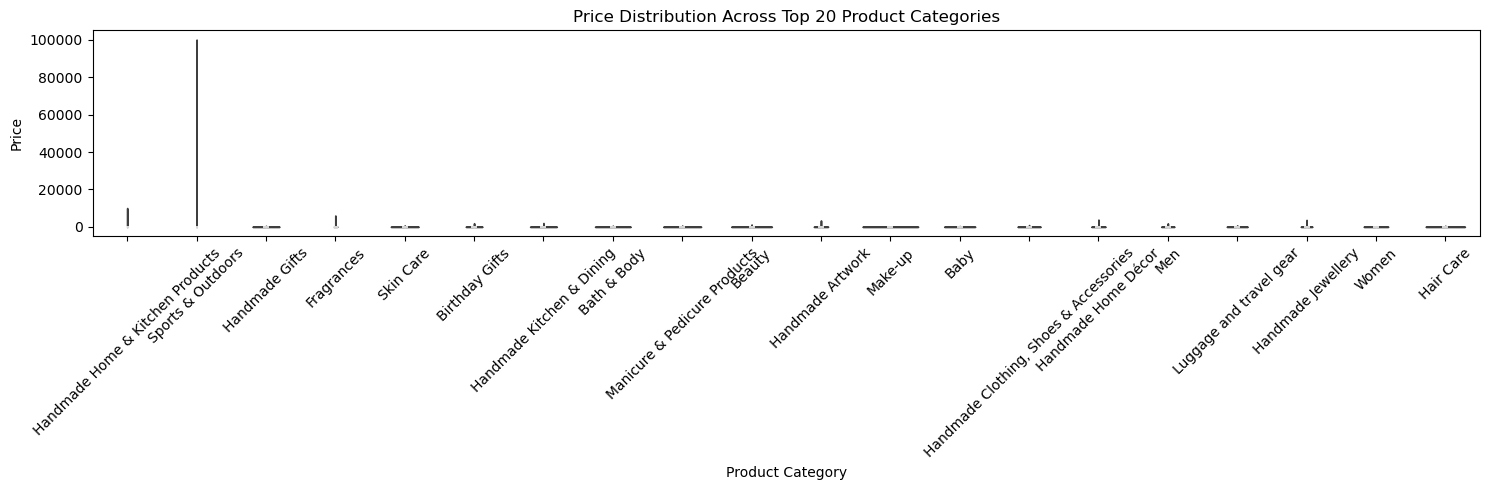

In [52]:
#Violin Plots:

top_categories = df_Amazon['category'].value_counts().head(20).index

filtered_df = df_Amazon[df_Amazon['category'].isin(top_categories)]

plt.figure(figsize=(15, 5))
sns.violinplot(x='category', y='price', data=filtered_df)
plt.xticks(rotation=45)
plt.title('Price Distribution Across Top 20 Product Categories')
plt.xlabel('Product Category')
plt.ylabel('Price')
plt.tight_layout()
plt.show()

In [68]:
highest_median_price = df_Amazon.groupby('category')['price'].median().sort_values(ascending=False)
highest_median_price 



category
Laptops                      1042.725
Desktop PCs                   810.400
Snowboards                    366.725
Home Audio Record Players     326.080
3D Printers                   319.000
                               ...   
Adapters                        7.050
Make-up                         7.000
Signs & Plaques                 6.990
Arts & Crafts                   5.990
Office Paper Products           4.380
Name: price, Length: 296, dtype: float64

In [69]:
highest_price= highest_median_price.max() # max(): Returns the maximum median price value itself
highest_price

1042.725

In [70]:
highest_category = highest_median_price.idxmax() #idxmax(): Returns the label of the maximum value, which is the category 
highest_category

'Laptops'

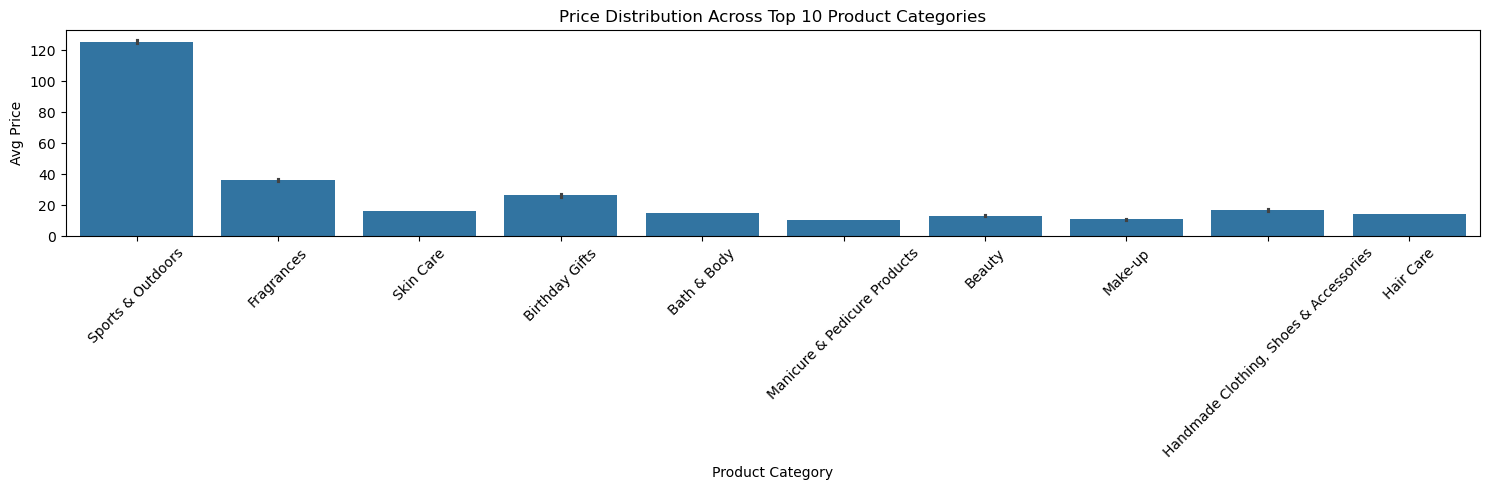

In [73]:
# Bar chart 

# first filter 
top_categories = df_Amazon['category'].value_counts().head(10).index
filtered_df = df_Amazon[df_Amazon['category'].isin(top_categories)]

#second filter
median_prices = filtered_df.groupby('category')['price'].median().sort_values(ascending=False) # pandas series --> index is category and value is price bit cannot be read by libraries sn or plt
median_prices_df = median_prices.reset_index()

#reset_index(), you transform the Series into a DataFrame. This operation turns the index of the Series (which consisted of product categories) into a regular column, 

plt.figure(figsize=(15, 5))
sns.barplot(x='category', y='price', data=filtered_df) # i need to add a filtered df both with top 10 category and median value
plt.xticks(rotation=45)
plt.title('Price Distribution Across Top 10 Product Categories')
plt.xlabel('Product Category')
plt.ylabel('Avg Price')
plt.tight_layout()
plt.show()

In [ ]:
# Category sports & outdoors have the highest meadian price

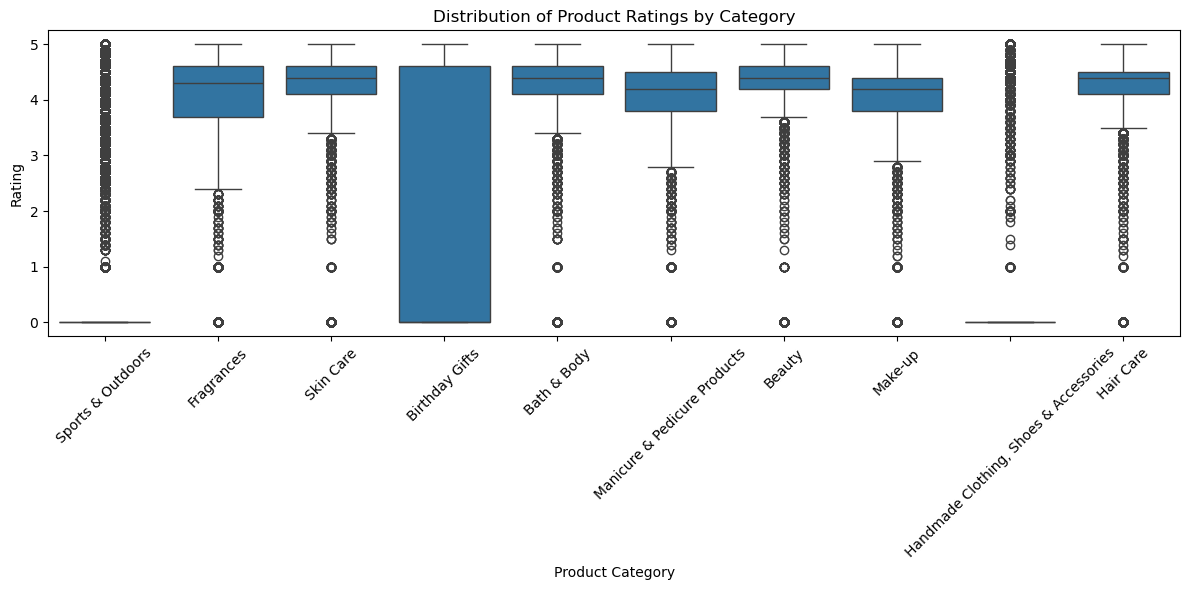

In [77]:
#3 Box plot --> central tendency and variability of the data, highlighting the median, quartiles, and potential outliers.


#Median (line inside box) → typical rating
#Box (Q1–Q3) → middle 50% of ratings
#Whiskers → typical min/max (excluding outliers)
#Dots → outliers (unusually low or high ratings)

top_category = df_Amazon['category'].value_counts().head(10).index
filtered_df = df_Amazon[df_Amazon['category'].isin(top_category)]

plt.figure(figsize=(12, 6))
sns.boxplot(x='category', y='stars', data=filtered_df)
plt.title('Distribution of Product Ratings by Category')
plt.xlabel('Product Category')
plt.ylabel('Rating')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [79]:
df_Amazon[df_Amazon['category'] == 'Sports & Outdoors']['stars'].describe() #Very small number of observation

count    836265.000000
mean          0.735162
std           1.639227
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max           5.000000
Name: stars, dtype: float64

In [81]:
df_Amazon[df_Amazon['category'] == 'Sports & Outdoors']['stars'].value_counts()

stars
0.0    692423
5.0     26535
4.5     14178
4.4     12730
4.6     11894
4.3     10592
4.0     10033
4.2      8960
4.7      8380
4.1      6820
4.8      4406
3.9      4316
3.8      3388
3.0      2948
3.7      2608
3.6      2302
3.5      2219
1.0      2173
3.4      1449
4.9      1240
3.3      1239
2.0      1001
3.2       907
3.1       790
2.9       516
2.8       422
2.5       395
2.7       352
2.6       266
2.4       194
2.3       112
2.1       104
2.2       102
1.5        84
1.9        51
1.4        42
1.8        35
1.7        27
1.6        20
1.3        11
1.1         1
Name: count, dtype: int64

In [ ]:
# category hair care has the highest median rating from customer 
# biggest disappointment is regoistered in Fragrance cat

## Part 3: Investigating the Interplay Between Product Prices and Ratings

**Correlation Coefficient (Pearson's r)**

- Meaning & Usage: This is a numerical measure that indicates the strength and direction of a linear relationship between two variables. The value ranges from -1 to 1. A value close to 1 implies a strong positive correlation, close to -1 implies a strong negative correlation, and around 0 indicates no correlation.

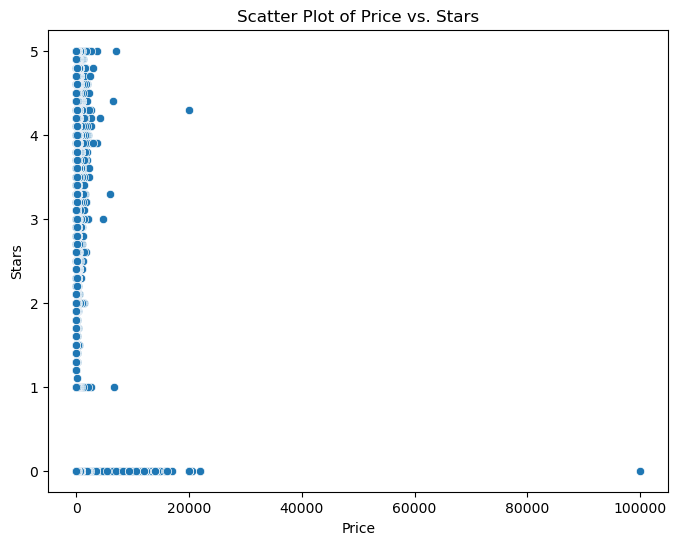

In [82]:
#scatter plot to understand the relationship 

plt.figure(figsize=(8, 6))
sns.scatterplot(x='price', y='stars', data=filtered_df)
plt.title('Scatter Plot of Price vs. Stars')
plt.xlabel('Price')
plt.ylabel('Stars')
plt.show()


In [ ]:
#Extreme price outlier (~100,000) --> Pearson correlation is very sensitive to outliers /  distort results significantly
# dataset is price-skewed
# A large number of points at rating = 0 --> 0 might be excluded or investigated
# No obvious linear relationship -->no upward or downward trend --> weak relation between price vs rating
# monotonic relationship might be more precise


In [84]:
df_Amazon['price'].describe()

count    2.443651e+06
mean     8.924381e+01
std      3.456089e+02
min      0.000000e+00
25%      9.990000e+00
50%      1.909000e+01
75%      4.599000e+01
max      1.000000e+05
Name: price, dtype: float64

In [ ]:
# mean 89 euro vs medial 50% 19 euro --> mean > median right skewed 
# very high prices pull the mean upward

# 75% of products are priced 46 euro or less while the mean is 89 euro --> long right skewed tail 

# 75 % vs max --> huge gap means there are few very expensive items and many unexpensive items

# Std > Mean --> This often happens in highly skewed distributions with outliers.

In [86]:
df_Amazon['price'].skew() 

# > 1 highly skewed 
# = 0 symmetric 
# < 0 left skewed 

np.float64(27.492977566280338)

In [89]:
from scipy.stats import pearsonr


# Step 2: Calculate the Pearson correlation coefficient
corr_coefficient, p_value = pearsonr(df_Amazon['price'], df_Amazon['stars'])  # vs spearman  -1 vs +1


print(f"Correlation Coefficient: {corr_coefficient}")
print(f"P-value: {p_value}")

if p_value < 0.05:
    print("There is a statistically significant correlation between price and stars.")
else:
    print("There is no statistically significant correlation between price and stars.")

Correlation Coefficient: -0.12490673262148612
P-value: 0.0
There is a statistically significant correlation between price and stars.


In [ ]:
# correlation coefficient  close to 0 --> weak relation between price & rating 
# negative --> if price increases, the rating tend to decrease


# p-value is is 0.0 is close to zero meaning that the relation is significant despite being weak 
# A p-value lower than 0.05 typically suggests that we can reject the null hypothesis of no correlation.

# This means that changes in price do not strongly impact ratings.

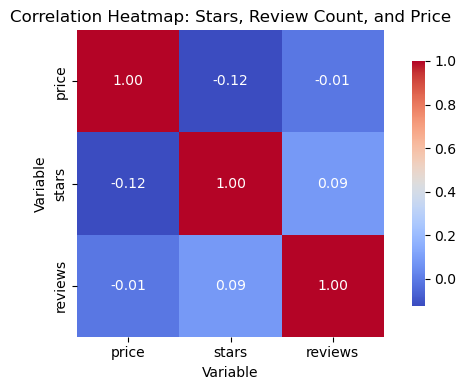

In [90]:
# heatmap plot stars vs review vs prices

# pandas to calculate the correlation coefficients between these columns
# seaborn to create visuals 

# Step 1: Select relevant columns
relevant_cols = df_Amazon[['price', 'stars', 'reviews']]

# Step 2: Compute the correlation matrix for these columns
corr_matrix = relevant_cols.corr()

# Step 3: Plot the heatmap

plt.figure(figsize=(6, 4))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', square=True, cbar_kws={"shrink": .8})   #annotations 
plt.title('Correlation Heatmap: Stars, Review Count, and Price')
plt.xlabel('Variable')
plt.ylabel('Variable')
plt.tight_layout()
plt.show()



In [ ]:
# red means strong posive correlation

# price vs reviews -0.01 negligible 
# price vs stars negative weak correlation--> higher price lower stars
# stars vs review 0.09 weak positive correlation --> product with more review have a bit more ratings
# star vs price -0.12 weak neg relation --> higher priced products have marginally lower ratings

# > 50 indicate significant values 

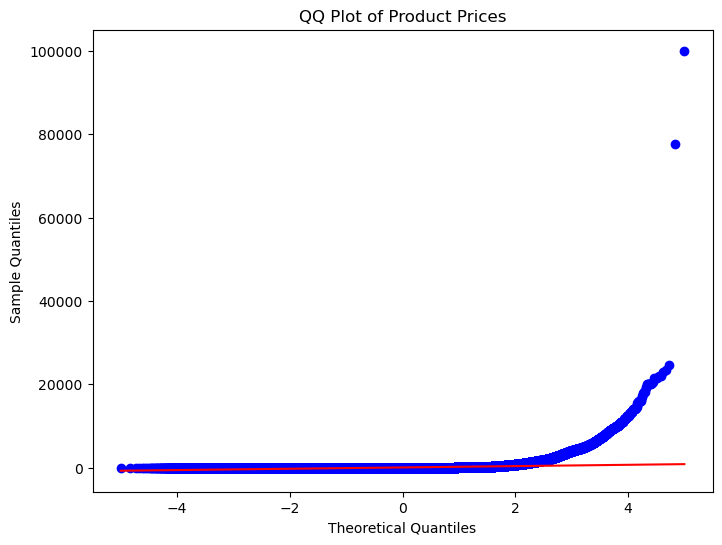

In [91]:
# QQ plot --> Data vs. Theoretical Quantiles: The plot comparisons are made between the quantiles of your data and the quantiles of the theoretical distribution you're comparing against (e.g., normal distribution)

import scipy.stats as stats

# Create a QQ plot to test for normality

plt.figure(figsize=(8, 6))
stats.probplot(df_Amazon['price'], dist="norm", plot=plt)
plt.title('QQ Plot of Product Prices')
plt.xlabel('Theoretical Quantiles')
plt.ylabel('Sample Quantiles')
plt.show()


In [92]:
# X-axis: Expected quantiles from a normal distribution.
# Y-axis: Observed quantiles from your sample data

#If your data closely follows a normal distribution, you will see the data points closely following the red line - the line of perfect normality
# Deviations from this line suggest that your data might not be normally distributed --> right skewed ( uoward curve far from the red line) too many large values from the symetrical distribution